In [1]:
import torch
from torchvision import transforms
import torch.optim as optim
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

In [2]:
def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

In [36]:
transform = transforms.Compose([
    transforms.Pad(4),
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(34),
    transforms.ToTensor()])

batch_size = 64

dataset = torchvision.datasets.CIFAR10('./datasets/data',train=True, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)


Files already downloaded and verified


In [5]:
import torch.nn as nn
# 3x3 convolution
def conv3x3(in_channels, out_channels, stride=1):
    return nn.Conv2d(in_channels, out_channels, kernel_size=3, 
                     stride=stride, padding=1, bias=False)

# Residual block
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, downsample=None):
        super(ResidualBlock, self).__init__()
        self.conv1 = conv3x3(in_channels, out_channels, stride)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = conv3x3(out_channels, out_channels)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.downsample = downsample

    def forward(self, x):
        residual = x
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        if self.downsample:
            residual = self.downsample(x)
        out += residual
        out = self.relu(out)
        return out

# ResNet
class ResNet(nn.Module):
    def __init__(self, block, layers, num_classes=10):
        super(ResNet, self).__init__()
        self.in_channels = 16
        self.conv = conv3x3(3, 16)
        self.bn = nn.BatchNorm2d(16)
        self.relu = nn.ReLU(inplace=True)
        self.layer1 = self.make_layer(block, 16, layers[0])
        self.layer2 = self.make_layer(block, 32, layers[1], 2)
        self.layer3 = self.make_layer(block, 64, layers[2], 2)
        self.avg_pool = nn.AvgPool2d(8)
        self.fc = nn.Linear(64, num_classes)

    def make_layer(self, block, out_channels, blocks, stride=1):
        downsample = None
        if (stride != 1) or (self.in_channels != out_channels):
            downsample = nn.Sequential(
                conv3x3(self.in_channels, out_channels, stride=stride),
                nn.BatchNorm2d(out_channels))
        layers = []
        layers.append(block(self.in_channels, out_channels, stride, downsample))
        self.in_channels = out_channels
        for i in range(1, blocks):
            layers.append(block(out_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x):
        out = self.conv(x)
        out = self.bn(out)
        out = self.relu(out)
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.avg_pool(out)
        out = out.view(out.size(0), -1)
        out = self.fc(out)
        return out

cifar_model = ResNet(ResidualBlock, [9, 9, 9])

In [34]:
new_cifar_model = torch.torch.torch.nn.Sequential(*(list(cifar_model.children())[:-2]))
last_layers = torch.torch.torch.nn.Sequential(*(list(cifar_model.children())[-2:]))
criterion = torch.nn.CrossEntropyLoss()
optimizer = optim.SGD(new_cifar_model.parameters(), lr=0.001, momentum=0.9)

In [7]:
print(last_layers)

Sequential(
  (0): AvgPool2d(kernel_size=8, stride=8, padding=0)
  (1): Linear(in_features=64, out_features=10, bias=True)
)


In [2]:
def attention_scores(q, k, v, mask=None):
    """
    Implementation of the cross-attention and the self-attention.
    Args:
        q: tensor of shape [B, T_Q, D_K]
        k: tensor of shape [B, T_V, D_K]
        v: tensor of shape [B, T_V, D_V]
    Output:
        out: tensor of shape [B, T_Q, D_v]
    """
    B = q.shape[0]
    #print(f'k shape is {k.shape}')
    scale = math.sqrt(k.shape[2])
    att = torch.bmm(q, k.transpose(1, 2)) / scale # [B, T_Q, T_V]
    # print(f'att shape is {att.shape}')
    if mask is not None:
        mask = mask.unsqueeze(0).repeat(B, 1, 1)
        att = torch.where(mask > 0.0, att, - math.inf * torch.ones_like(att))
#     att = F.softmax(att, 2)
#     print(f'att shape is {att.shape}')
#     out = torch.bmm(att, v)
#     print(f'out shape is {out.shape}')
#     return out
#    # print(f'after attention scores is {att.shape}')
    return att


##################################################
# Attention layers
##################################################

class HeadScores(nn.Module):
    """
    Attention is all you need, Vaswani et al, 2017.
    https://arxiv.org/abs/1706.03762
    ::
             Linear proj.     Linear proj.     Linear proj.
               (query: q)       (key: k)        (value: v)
                  ↓                ↓                ↓
                   --------        |        --------
                           ↓       ↓       ↓
                          Attention (q, k, v)
    """
    def __init__(self, h_dim, head_out_dim):
        super().__init__()
        self.q_lin = nn.Linear(h_dim, head_out_dim, bias=False)
        self.k_lin = nn.Linear(h_dim, head_out_dim, bias=False)
        self.v_lin = nn.Linear(h_dim, head_out_dim, bias=False)

    def forward(self, q, k=None, v=None, mask=None):
        q= torch.transpose(q, 1,2)
        if k is None:
            k = q
        if v is None:
            v = k
        #print(f'q shape is {q.shape}')
        q = self.q_lin(q)
        #print(f'q shape after linearization is {q.shape}')
        k = self.k_lin(k)
        v = self.v_lin(v)
        x = attention_scores(q, k, v, mask=mask) # [B, NUM_PATCH, NUM_PATCH]
        return x

class MultiHeadAttentionScores(nn.Module):
    """
    Attention is all you need, Vaswani et al, 2017.
    https://arxiv.org/abs/1706.03762
    ::
            [Head_1, Head_2, ..., Head_h]
                           ↓
                       Cat (dim=2)
                           ↓
            Linear (in=h * h_dim, out=h_dim)
    """
    def __init__(self, h_dim, num_heads):
        super().__init__()
        self.h_dim = h_dim
        self.num_heads = num_heads
        self.heads = nn.ModuleList([
            HeadScores(h_dim, h_dim // num_heads) for _ in range(num_heads)
        ])
        self.linear = nn.Linear((h_dim // num_heads) * num_heads, h_dim)

    def forward(self, input, k=None, v=None, mask=None):
        B, num_patches = input.shape[0:2]
        q= input.reshape(B, num_patches, -1)
        x = [head(q, k, v, mask=mask) for head in self.heads]
        x = torch.stack(x, 1) # [B, num_heads, NUM_PATCH, NUM_PATCH]
        # x = self.linear(x) # [B, T, h_dim]
        return x


In [40]:
rel_head = MultiHeadAttentionScores(81, 9)
model = nn.Sequential(
    new_cifar_model,
    rel_head,
)
x = new_cifar_model(inputs)
print(x.shape)


torch.Size([64, 64, 9, 9])


In [3]:
def cross_entropy(logits, labels, smooth=0.0, dropout=0.0):
    """
    Compute the cross entropy.
    Args:
        logits: tensor of shape [bs, num_classes(, ...)].
        labels: tensor of shape [bs(, num_classes, ...)].
        smooth: scalar, for label smoothing.
    Output:
        xent: scalar.
    """
    if smooth == 0.0:
        return F.cross_entropy(logits, labels)

    logprobs = F.log_softmax(logits, dim=1)
    nll_loss = - logprobs.gather(dim=1, index=labels.unsqueeze(1))
    nll_loss = nll_loss.squeeze(1)
    smooth_loss = - logprobs.mean(dim=1)
    loss = (1.0 - smooth) * nll_loss + smooth * smooth_loss 
    if dropout > 0.0:
        loss = F.dropout(loss, p=dropout)
    return loss.mean()

def accuracy(preds, labels, preds_with_logits=True):
    """
    Compute the accuracy.

    Args:
        preds: tensor of shape [bs, num_classes(, ...)].
        labels: tensor of shape [bs(, ...)].
        preds_with_logits: bool.

    Output:
        acc: scalar.
    """
    if preds_with_logits:
        preds = F.softmax(preds, 1)
    preds = preds.argmax(1)
    acc = (1.0 * (preds == labels)).mean()
    return acc

In [11]:
## per creazione del target 
## patches sarà il vettore contenente tutte le 64 posizioni delle patches.(TR, TC, TL ecc..) alto destra, alto sinistra, alto in centro ...
def create_patch_matrix(num_patches):
    side = int(math.sqrt(num_patches))
    patches = np.arange(num_patches).reshape(side, side)
    return patches

def create_label_matrix(num_patches):
    """
    Create the spatial location matrix (as the example above).
    """
    labels = np.arange(9) # Spatial location encoded as int...
    labels_matrix = labels.reshape(3, 3)
    patch_matrix_side = int(math.sqrt(num_patches))

    side = 2 * patch_matrix_side - 1
    lu, cu, ru = labels_matrix[0, 0], labels_matrix[0, 1], labels_matrix[0, 2]
    lc, cc, rc = labels_matrix[1, 0], labels_matrix[1, 1], labels_matrix[1, 2]
    ld, cd, rd = labels_matrix[2, 0], labels_matrix[2, 1], labels_matrix[2, 2]

    corner_side = int((side - 1) / 2)
    cor = np.ones([corner_side, corner_side]).astype(labels.dtype)
    cen = np.ones([1, 1]).astype(labels.dtype)
    ver = np.ones([corner_side, 1]).astype(labels.dtype)
    hor = np.ones([1, corner_side]).astype(labels.dtype)

    labels_matrix = np.concatenate([
        np.concatenate([lu * cor, cu * ver, ru * cor], 1),
        np.concatenate([lc * hor, cc * cen, rc * hor], 1),
        np.concatenate([ld * cor, cd * ver, rd * cor], 1),
    ], 0)

    return labels_matrix

def create_connectivity_matrix(patches):
    patch_flat = patches.reshape(-1)
    print(f'patch_flat {patch_flat.size}')
    num_patches = len(patch_flat)
    print(f'num_patches {num_patches}')
    labels_matrix = create_label_matrix(num_patches)

    side = int(math.sqrt(num_patches))
    conn_matrix = - 1 * np.ones([num_patches, num_patches]).astype(labels_matrix.dtype)
    center = int((labels_matrix.shape[0] - 1) / 2)
    for i in range(side):
        for j in range(side):
            labels_ij_matrix = labels_matrix[center - i: center - i  + side, center - j: center - j  + side]
            labels_ij_matrix = labels_ij_matrix.reshape(-1)
            #idx_flat = patch_flat[i * side + j]
            idx_flat = i * side + j
            conn_matrix[idx_flat, :] = labels_ij_matrix

    conn_matrix = conn_matrix.T
    conn_matrix = conn_matrix[patch_flat, :][:, patch_flat]
    return conn_matrix

num_patches = 2025
side = int(np.sqrt(num_patches))
patches_init = torch.arange(num_patches).reshape(side, side).numpy()
print(f'patches_init shape {patches_init.shape}')
conn_matrix = create_connectivity_matrix(patches_init)
conn_matrix = torch.from_numpy(conn_matrix).to(torch.int64)
print(f'conn_matrix shape {conn_matrix.shape}')
target = conn_matrix.unsqueeze(0).repeat(batch_size, 1, 1)


patches_init shape (45, 45)
patch_flat 2025
num_patches 2025
conn_matrix shape torch.Size([2025, 2025])


In [ ]:
# for epoch in range(5):  # loop over the dataset multiple times
#     running_loss = 0.0
#     for i, data in enumerate(trainloader, 0):
#         inputs, labels = data
#         outputs = model(inputs)
#         target = conn_matrix.unsqueeze(0).repeat(outputs.shape[0], 1, 1)
#         loss = cross_entropy(outputs, target)
#         loss.backward()
#         # optimizer.step()
#         running_loss += loss.item()
#         acc_rel = accuracy(outputs, target)
#         if i % 2000 == 1999:    # print every 2000 mini-batches
#             print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f} accuracy: {acc_rel / 2000:.3f}')
#             running_loss = 0.0

# print('Finished Training')

In [15]:
model.named_parameters()

<generator object Module.named_parameters at 0x1391133c0>

In [38]:
inputs, classes = next(iter(trainloader))  

In [ ]:
print(f'input size {inputs.shape}')
out = new_cifar_model(inputs)
print(f'resnet output {out.shape}')
out1 = rel_head(out)
print(f'attention layer {out1.shape}')
print(conn_matrix.shape)
print(conn_matrix)
target = conn_matrix.unsqueeze(0).repeat(64, 1, 1)
print(target.shape)
loss = cross_entropy(out1,target)
print(loss.item())
# print(x.shape)
# print(x)
# b = x.repeat(4,2)
# print(b.shape)
# print(b)

In [21]:
#import pytorch_lightning as pl
import torch
from torchvision import transforms
import torch.optim as optim
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import torchvision.models as models

transform = transforms.Compose(
    [transforms.Resize(224),
    transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 1

dataset = torchvision.datasets.CIFAR10('./datasets/data',train=True, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

inputs, classes = next(iter(trainloader))  

model = models.resnet50()
first_part = torch.torch.torch.nn.Sequential(*(list(model.children())[:-2]))
last_layers = torch.torch.torch.nn.Sequential(*(list(model.children())[-2:]))
layer = torch.torch.torch.nn.Sequential(*(list(model.children())[:5]))


Files already downloaded and verified


In [25]:
# print(layer)
print(model.layer1)

Sequential(
  (0): Bottleneck(
    (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (downsample): Sequential(
      (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
  )
  (1): Bottleneck(
    (conv1): Conv2d(256, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv2): Conv2d(64, 64, ke

In [6]:

class Flatten(nn.Module):
    def __init__(self):
        super(Flatten, self).__init__()
        
    def forward(self, x):
        print(x.shape)
        x = x.view(x.size(0), -1)
        print(x.shape)
        return x

In [ ]:
pytorch_total_params = sum(p.numel() for p in model.parameters())
print(pytorch_total_params)

small_net = sum(p.numel() for p in cifar_model.parameters())
print(small_net)

25557032
876250


In [67]:
att_layer = MultiHeadAttentionScores(49, 9) 
linear = nn.Linear(2048, 2025)

print(f'input size {inputs.shape}')
out = first_part(inputs)
print(f'resnet output {out.shape}')
out = out.transpose(1,3)
out_lin = linear(out)
print(f'reshapet {out_lin.shape}')
out = out_lin.transpose(1,3)
out1 = att_layer(out)
print(f'attention layer {out1.shape}')
print(f'connection matrix {conn_matrix.shape}')
target = conn_matrix.unsqueeze(0).repeat(1, 1, 1)
print(f'target shape is {target.shape}')
loss = F.cross_entropy(out1,target)
print(loss.item())
# print(x.shape)
# print(x)
# b = x.repeat(4,2)
# print(b.shape)
# print(b)


NameError: name 'first_part' is not defined

In [128]:
def to_rgb_ifneeded(x):
    """
    Given a PIL Image x it returns its rgb converted version, if x is not rgb.
    """
    return x.convert('RGB') if x.mode in ['L', 'RGBA'] else x

transform= transforms.Compose([
                    to_rgb_ifneeded,
                    transforms.RandAugment(num_ops = 5),
                    transforms.ToTensor(),
                ])

batch_size = 64

dataset = torchvision.datasets.CIFAR10('./datasets/data',train=True, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

Files already downloaded and verified


In [129]:
len(dataset)

50000

In [1]:
%reload_ext autoreload

from Models import resnet_cifar10

original_model = resnet_cifar10.resnet56()
class_layer = torch.nn.Sequential(*(list(original_model.children())[-2:]))
model = torch.nn.Sequential(*(list(original_model.children())[:-2]))
print(class_layer.state_dict)

NameError: name 'torch' is not defined

In [66]:
inputs, _ = next(iter(trainloader))

In [69]:
att_layer = MultiHeadAttentionScores(64, 9) 

print(f'input size {inputs.shape}')
out = model(inputs)
print(f'resnet output {out.shape}')
B, C, H, W = out.shape
out1 = att_layer(out)
print(f'attention layer {out1.shape}')
x_rel = out1.transpose(1, 2).reshape(B, 9, H * H, W * W)
print(f'attention layer transope {x_rel.shape}')
# print(f'connection matrix {conn_matrix.shape}')
# target = conn_matrix.unsqueeze(0).repeat(1, 1, 1)
# print(f'target shape is {target.shape}')
# loss = F.cross_entropy(out1,target)
# print(loss.item())

input size torch.Size([64, 3, 34, 34])
resnet output torch.Size([64, 64, 9, 9])
attention layer torch.Size([64, 9, 81, 81])
attention layer transope torch.Size([64, 9, 81, 81])


In [ ]:
a = resnet_cifar10.__dict__['resnet56']()
b = models.__dict__['resnet50']()
# print(a.linear.in_features)
# (226//64)**2
print(list(a.children())[-1].in_features)
print(list(b.children())[-1].in_features)
print(a[-1])


In [3]:
from datasets.dataloaders import get_datasets, get_dataloaders
from config import get_args
class fakeArgs:
    def __init__ (self, dataset, task='downstream'):
        self.dataset = dataset
        self.img_height = 224
        self.patch_size = 32
        self.data_base_path = './datasets/data'
        self.task = task
        self.use_relations = True
        self.use_distances = False
        self.use_angles = False
        self.use_abs_positions = False
        self.debug_dataset = False
        self.mega_patches = False
        self.side_megapatches = False
        self.batch_size= 1
        self.num_workers= 0
        self.shuffle_patches = False
        self.use_randAugment = False
        self.use_segmentation = True
        
        
args = fakeArgs('ade20k')
dds = get_dataloaders(args)

Found 20210 images in the folder ./datasets/data
Found 20210 images in the folder ./datasets/data
Found 2000 images in the folder ./datasets/data
Found 20210 images in the folder ./datasets/data


In [4]:
print(len(dds['train_aug']))
print(len(dds['train']))
input_train = next(iter(dds['train']))
print(f"input shape {input_train['images'].shape}")
print(f"labels shape {input_train['labels'].shape}")
# print(input_train['labels'])


20210
20210
input shape torch.Size([1, 3, 224, 224])
labels shape torch.Size([1, 224, 224])


In [5]:
print(dds['train'])

In [5]:
def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

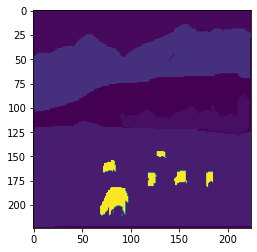

In [6]:
imshow(input_train['labels'])

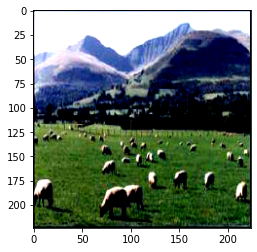

In [7]:
imshow(input_train['images'].squeeze())

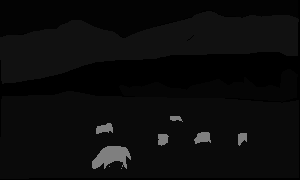

In [28]:
from IPython.display import Image, display
display(Image(input_train['mask_file'][0]))

In [ ]:
it = iter(dds['train'])
while it :
    data = next(it)
    mask = data['labels']
    print(mask.shape)
     

In [ ]:
from datasets.utils_ade20k import loadAde20K
data = loadAde20K('datasets/data/ADE20K_2021_17_01/images/ADE/training/transportation/airport_terminal/ADE_train_00000001.jpg')
print(f'keys: {data.keys()}')
# print(f'img_name: {data["img_name"]}')
# print(f'segm_name: {data["segm_name"]}')
# print(f"class_mask: {data['class_mask']}")
# print(f"instance_mask: {data['instance_mask'].shape}")
# print(f"partclass_mask: {data['partclass_mask']}")
# print(f"part_inscence_mask: {data['part_instance_mask']}")
print(f"objects: {data['objects']}")
# print(f"parts: {data['parts']}")


In [67]:
import pickle
with open('datasets/data/ADEChallengeData2016', 'rb') as f:
    items = pickle.load(f)
file_name_list = items['filename']
folder = items['folder']
print(len(file_name_list))
img_paths = []
mask_paths = []
for i, filename in enumerate(file_name_list):
    if 'train' in filename:
        img_paths += [os.path.join(folder[i], file_name_list[i])]
        mask_paths += [os.path.join(folder[i], file_name_list[i].replace('.jpg', '_seg.png'))]
        
print(len(img_paths))
print(len(mask_paths))

27574
25258
25258


In [29]:
from PIL import Image
list_img = os.listdir('datasets/data/ADEChallengeData2016/annotations/training')
print(len(list_img))
shape_list = []
for l in list_img:
    img = np.array(Image.open(os.path.join('datasets/data/ADEChallengeData2016/annotations/training',l)))
    shape_list += [img.shape]

20210


In [34]:
shape_list[0][0] < 224

False

In [39]:
count = 0
for s in shape_list:
    if s[0] < 224 and s[1] < 224:
        count +=1
print(count)

56


In [35]:
from Models.vit_dino import vit_dino

512